
# Exploratory Analysis of PM2.5 Air Quality Data in Morocco

**Author :** Oumayma Ihrissane  
**Start Date :** October 16, 2026

*Environmental Data Science · Exploratory Data Analysis*


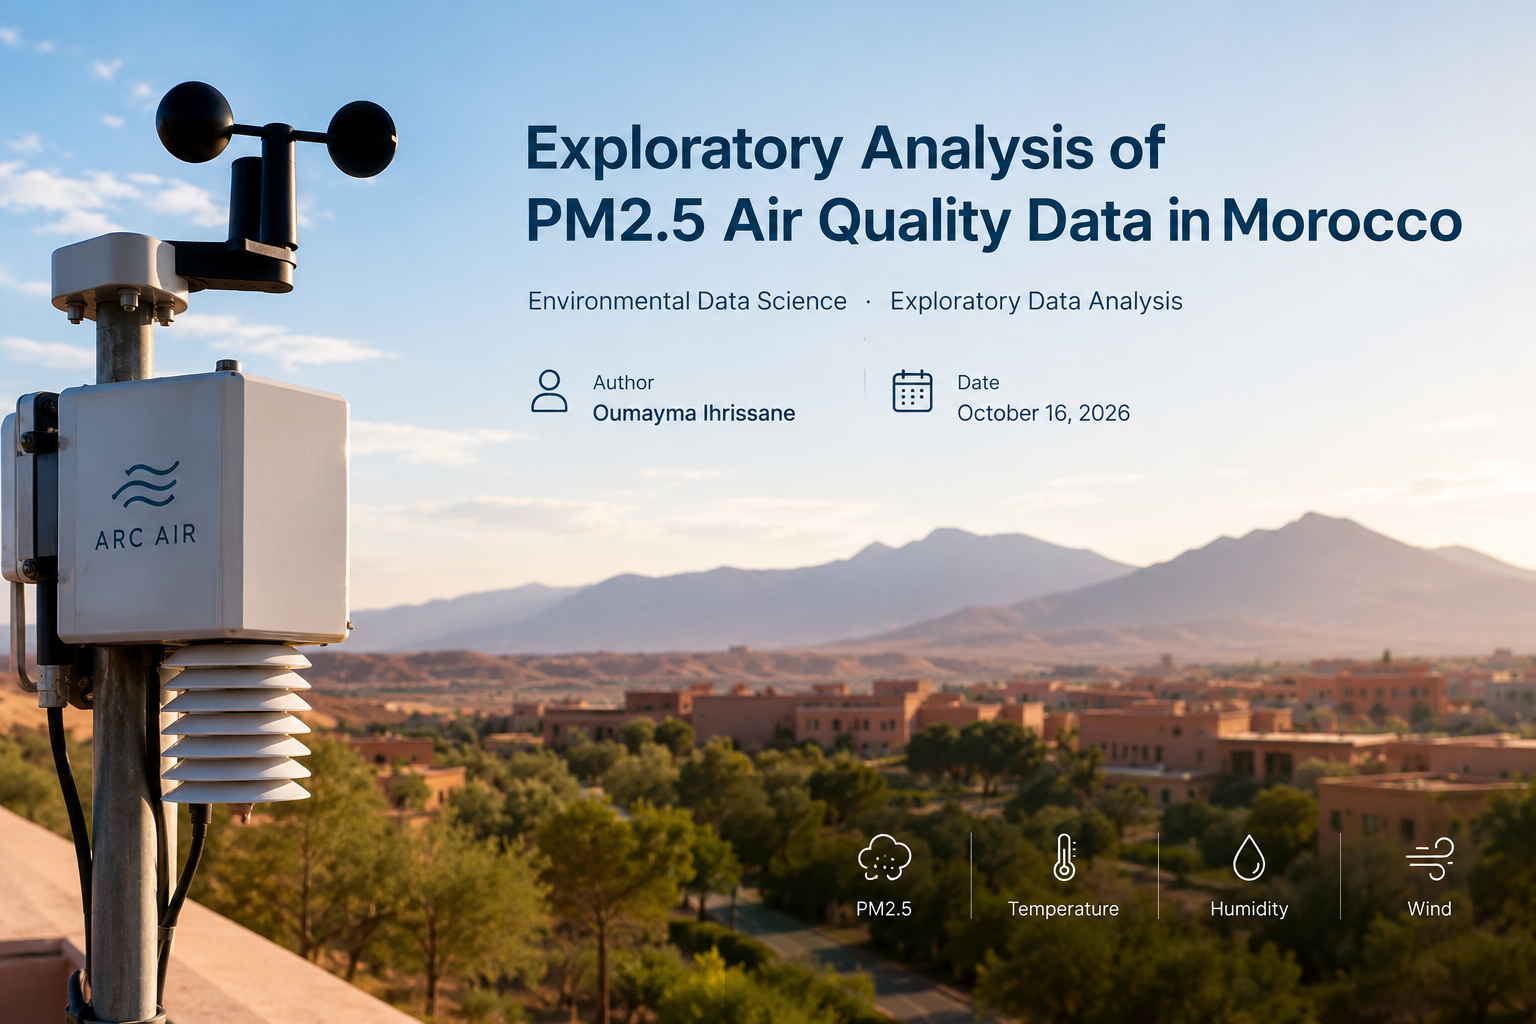


## Research Question

How do PM2.5 concentrations vary over time, and how are they associated with available meteorological conditions?

## Objectives

- Explore the temporal variation of PM2.5 concentrations.
- Investigate potential relationships between PM2.5 concentrations, temperature, and relative humidity.
- Assess the completeness and quality of the available data.
- Identify limitations and suggest directions for future research.





## **Step 0 : Understanding PM2.5**

- PM2.5 refers to fine particulate matter with an aerodynamic diameter of 2.5 micrometers (µm) or less. These particles consist of a mixture of solid particles and liquid droplets suspended in the air. They can originate from sources such as vehicle emissions, industrial activities, combustion, and atmospheric chemical reactions.

- PM2.5 is an important air quality indicator because these fine particles can penetrate deep into the lungs and are associated with adverse respiratory and cardiovascular health effects.

- Their concentrations can vary over time depending on emission sources and atmospheric conditions. Temperature and relative humidity may be associated with these variations, although their relationships can be complex.

> In this project, PM2.5 measurements from the ARC AIR monitoring station in Ben Guerir, Morocco, will be explored to examine temporal patterns, investigate potential relationships with meteorological variables, and assess data quality.

> **Scope:** This exploratory analysis aims to identify patterns and associations. It does not establish causal relationships or assess health impacts directly.

## **Step 1 : Import libraries and load the data**



In [ ]:
# Import libraries and connect Google Drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')


In [ ]:
# Load the OpenAQ CSV export from Google Drive
# Download the CSV from OpenAQ and upload it to the root of your Google Drive.
# Keep the filename below unchanged, or update FILE_PATH to match your filename.
FILE_PATH = Path(
    "/content/drive/MyDrive/openaq_location_3847229_measurments.csv"
)

if not FILE_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {FILE_PATH}\n"
        "Download the OpenAQ CSV export, upload it to Google Drive, "
        "and make sure the filename and path match FILE_PATH."
    )

df_raw = pd.read_csv(FILE_PATH)

print("Shape:", df_raw.shape)
display(df_raw.head())
df_raw.info()


## **Step 2 : Understand the dataset**

The OpenAQ export is in **long format**: each row contains one parameter reading. The same timestamp can therefore appear once for each parameter.

In [ ]:
print("Columns:")
print(df_raw.columns.tolist())

print("\\nRows per parameter:")
display(df_raw["parameter"].value_counts(dropna=False))

print("\\nUnits per parameter:")
display(df_raw.groupby("parameter")["unit"].unique())

print("\\nLocation(s):")
display(df_raw[["location_id", "location_name", "latitude", "longitude", "timezone", "provider"]].drop_duplicates())



## Preliminary Dataset Overview


---



- The dataset contains 5,000 rows and 15 columns, corresponding to five parameters with 1,000 records each: PM1, PM2.5, temperature, relative humidity, and particle number concentration (`um003`).

- All records are associated with a single OpenAQ location named ARC Air, identified by location ID 3847229. The dataset also includes measurement timestamps, geographic coordinates, units, and data provider information.

- The data are stored in long format, meaning that each row represents one parameter measurement at a given timestamp. This structure will be examined further to verify timestamp alignment and temporal coverage before conducting the exploratory analysis.

- Three metadata columns (`country_iso`, `isMobile`, and `isMonitor`) contain no values in this export and will not be used in the analysis unless additional metadata become available.

> These checks describe the dataset's structure. The following steps assess timestamp alignment and temporal coverage; additional sensor validation and contextual data would be needed to assess the causes and reliability of extreme observations.

## **Step 3 : Data quality checks**

Parse timestamps, check missing values and duplicate parameter-timestamp pairs, and inspect the time coverage. We will not impute values at this stage.

In [ ]:
df = df_raw.copy()

# Parse timestamps consistently, then convert to the station's local timezone.
df["datetimeLocal"] = pd.to_datetime(df["datetimeLocal"], errors="coerce", utc=True)
df["datetimeLocal"] = df["datetimeLocal"].dt.tz_convert("Africa/Casablanca")
df["value"] = pd.to_numeric(df["value"], errors="coerce")

print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("Duplicate parameter-timestamp pairs:",
      df.duplicated(subset=["parameter", "datetimeLocal"]).sum())

print("Invalid timestamps:", df["datetimeLocal"].isna().sum())
print("Date range:", df["datetimeLocal"].min(), "to", df["datetimeLocal"].max())
print("Unique timestamps:", df["datetimeLocal"].nunique())

quality_by_parameter = (
    df.groupby("parameter")
      .agg(
          rows=("value", "size"),
          missing_values=("value", lambda s: s.isna().sum()),
          min_value=("value", "min"),
          median_value=("value", "median"),
          mean_value=("value", "mean"),
          max_value=("value", "max"),
          unit=("unit", "first")
      )
)
display(quality_by_parameter)


### **Step 4 : Check hourly continuity**

A dataset can have no missing values in its existing rows and still have missing hours. This check identifies gaps in the timeline.

In [ ]:

# Count how many distinct parameters are available at each timestamp
parameters_per_hour = (
    df.dropna(subset=["datetimeLocal"])
      .groupby("datetimeLocal")["parameter"]
      .nunique()
)

print("Number of parameters available per timestamp:")
display(parameters_per_hour.value_counts().sort_index())

# Check whether all five parameters are present at each timestamp
expected_parameters = 5

incomplete_hours = parameters_per_hour[
    parameters_per_hour != expected_parameters
]

print("Total unique timestamps:", len(parameters_per_hour))
print("Timestamps with all five parameters:",
      (parameters_per_hour == expected_parameters).sum())
print("Timestamps with fewer or more than five parameters:",
      len(incomplete_hours))

display(incomplete_hours.head(20))


## **Step 5 : Data Restructuring and Validation**

In [ ]:

# Create a separate dataframe for analysis
df_analysis = df.copy()

# Remove columns that are entirely empty
df_analysis = df_analysis.dropna(axis=1, how="all")

# Remove station metadata and other fields not needed for temporal analysis
columns_to_drop = [
    "location_id",
    "location_name",
    "latitude",
    "longitude",
    "timezone",
    "country_iso",
    "isMobile",
    "isMonitor",
    "owner_name",
    "provider",
    "datetimeUtc"
]

df_analysis = df_analysis.drop(
    columns=columns_to_drop,
    errors="ignore"
)

# Convert the dataset from long format to wide format
df_wide = df_analysis.pivot(
    index="datetimeLocal",
    columns="parameter",
    values="value"
).reset_index()

# Clean up the column index created by pivot
df_wide.columns.name = None

# Sort chronologically
df_wide = df_wide.sort_values("datetimeLocal").reset_index(drop=True)

print("Wide dataset shape:", df_wide.shape)
display(df_wide.head())
df_wide.info()


In [ ]:

# Verify the structure of the wide dataset
print("Number of rows:", len(df_wide))
print("Number of unique timestamps:", df_wide["datetimeLocal"].nunique())

measurement_columns = [
    "pm1", "pm25", "relativehumidity", "temperature", "um003"
]

print("\nMissing values after pivot:")
display(df_wide[measurement_columns].isna().sum())

print("\nDuplicate timestamps:", df_wide["datetimeLocal"].duplicated().sum())


### Data Restructuring — Summary


---



- The dataset was successfully transformed from **long format** into **wide format**, resulting in 1,000 rows and six columns: one timestamp column and five measurement variables. All five parameters are available at every timestamp, with no missing measurement values or duplicate timestamps.

- The resulting dataset is consistent and ready for exploratory data analysis (EDA), starting with the distribution of PM2.5 concentrations and their temporal variations.

## **Step 6: Exploratory Data Analysis (EDA) — PM2.5**


### **6.1: Descriptive Statistics of PM2.5**

In [ ]:
# Select PM2.5 concentrations
pm25 = df_wide["pm25"]

# Calculate descriptive statistics
pm25_stats = pm25.describe().to_frame(name="PM2.5 (µg/m³)")

display(pm25_stats)


### **6.2: Distribution of PM2.5 Concentrations**

In [ ]:
# Plot the distribution of PM2.5 concentrations
plt.figure(figsize=(9, 5))

plt.hist(
    df_wide["pm25"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of PM2.5 Concentrations")
plt.xlabel("PM2.5 Concentration (µg/m³)")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


> **PM2.5 Distribution — Key Findings**

- The PM2.5 distribution is positively skewed, with most observations concentrated at relatively low to moderate levels and a smaller number of substantially higher values.
- This pattern is consistent with the mean (14.56 µg/m³) being higher than the median (11.60 µg/m³).
- The maximum concentration of 123.2 µg/m³ warrants further investigation to determine its temporal context and assess whether it represents a genuine pollution episode or a potential measurement anomaly.

> The next step is to examine PM2.5 concentrations over time to identify temporal patterns and determine when the highest values occurred.

### **6.3: Temporal Variation of PM2.5**

In [ ]:
# Plot PM2.5 concentrations over time
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(
    df_wide["datetimeLocal"],
    df_wide["pm25"],
    linewidth=0.8
)

ax.set_title("PM2.5 Concentrations Over Time")
ax.set_xlabel("Local date and time")
ax.set_ylabel("PM2.5 Concentration (µg/m³)")

# Show a readable date label every two days; measurements remain hourly.
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2, tz=df_wide["datetimeLocal"].dt.tz))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M", tz=df_wide["datetimeLocal"].dt.tz))

ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


> ### **Temporal Variation of PM2.5 — Key Findings**

- PM2.5 concentrations fluctuate considerably over the observation period, with most measurements remaining below approximately 30 µg/m³ and several pronounced peaks.
- The highest observed concentration is approximately 123 µg/m³, occurring in early July. No clear overall increasing or decreasing trend is evident from the time series alone.
- Further investigation is needed to identify the timing of these peaks and explore their possible associations with meteorological conditions.

### **6.4: Identify and Investigate PM2.5 Peaks**

In [ ]:
# Identify the 10 highest PM2.5 concentrations
top_pm25 = (
    df_wide[["datetimeLocal", "pm25"]]
    .nlargest(10, "pm25")
    .sort_values("pm25", ascending=False)
    .reset_index(drop=True)
)

display(top_pm25)


### **PM2.5 Peaks — Key Findings and Conclusion**

- The analysis of the 10 highest PM2.5 concentrations revealed that elevated values were concentrated in specific periods, particularly on July 3–4, 2026.
- The maximum concentration reached 123.2 µg/m³ on July 4 at 04:00 local time, while another major peak of 105.3 µg/m³ occurred on June 12 at 07:00.
- These results suggest that some high concentrations occurred in short time windows rather than being evenly distributed throughout the observation period. However, the causes of these peaks cannot be determined from PM2.5 measurements alone.

> The next step is to explore the potential relationships between PM2.5 concentrations and meteorological variables, particularly temperature and relative humidity, to investigate whether these conditions are associated with changes in PM2.5 levels.

## **Step 7 : Exploring Relationships Between PM2.5 and Meteorological Variables.**

### **7.1 : PM2.5 and Temperature**

In [ ]:

# Plot PM2.5 concentrations against temperature
plt.figure(figsize=(8, 5))

plt.scatter(
    df_wide["temperature"],
    df_wide["pm25"],
    alpha=0.6
)

plt.title("PM2.5 Concentrations vs. Temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("PM2.5 Concentration (µg/m³)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
# Quantifying the Relationship Between PM2.5 and Temperature

# Calculate correlations between PM2.5 and temperature
pearson_corr = df_wide["pm25"].corr(
    df_wide["temperature"],
    method="pearson"
)

spearman_corr = df_wide["pm25"].corr(
    df_wide["temperature"],
    method="spearman"
)

print(f"Pearson correlation: {pearson_corr:.3f}")
print(f"Spearman correlation: {spearman_corr:.3f}")


### **Key Findings**

- Graph: significant dispersion, with no clear linear trend.

- Pearson (−0.212): weak negative linear association.

- Spearman (−0.331): somewhat more pronounced negative monotonic association.

> Interpretation : higher temperatures tend to be associated with lower PM2.5 concentrations in this sample, but this does not prove that temperature causes this decrease.

### **7.2 : PM2.5 and Relative Humidity**

In [ ]:

# Plot PM2.5 concentrations against relative humidity
plt.figure(figsize=(8, 5))

plt.scatter(
    df_wide["relativehumidity"],
    df_wide["pm25"],
    alpha=0.6
)

plt.title("PM2.5 Concentrations vs. Relative Humidity")
plt.xlabel("Relative Humidity (%)")
plt.ylabel("PM2.5 Concentration (µg/m³)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

# Calculate correlations between PM2.5 and relative humidity
pearson_rh = df_wide["pm25"].corr(
    df_wide["relativehumidity"],
    method="pearson"
)

spearman_rh = df_wide["pm25"].corr(
    df_wide["relativehumidity"],
    method="spearman"
)

print(f"Pearson correlation: {pearson_rh:.3f}")
print(f"Spearman correlation: {spearman_rh:.3f}")


### **Key Findings — PM2.5 and Relative Humidity**

- **Graph:** considerable dispersion, with a possible positive trend and several extreme values.

- **Pearson (0.230):** weak positive linear association.

- **Spearman (0.386):** a more pronounced positive monotonic association.

> **Interpretation:** higher relative humidity tends to be associated with higher PM2.5 concentrations in this sample. The association is more apparent when considering the ranks of the observations rather than only their linear relationship. However, this does not prove that higher humidity causes PM2.5 concentrations to increase.

### **7.3 — PM2.5 and PM1**

In [ ]:
# Plot PM2.5 concentrations against PM1
plt.figure(figsize=(8, 5))

plt.scatter(
    df_wide["pm1"],
    df_wide["pm25"],
    alpha=0.6
)

plt.title("PM2.5 Concentrations vs. PM1")
plt.xlabel("PM1 Concentration (µg/m³)")
plt.ylabel("PM2.5 Concentration (µg/m³)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

# Calculate correlations between PM2.5 and PM1
pearson_pm1 = df_wide["pm25"].corr(
    df_wide["pm1"],
    method="pearson"
)

spearman_pm1 = df_wide["pm25"].corr(
    df_wide["pm1"],
    method="spearman"
)

print(f"Pearson correlation: {pearson_pm1:.3f}")
print(f"Spearman correlation: {spearman_pm1:.3f}")


### **Key Findings — PM2.5 and PM1**

- **Graph:** a very strong positive linear pattern, with the observations closely clustered around an increasing trend. A few high-concentration observations are also visible.

- **Pearson (0.993):** extremely strong positive linear association.

- **Spearman (0.994):** extremely strong positive monotonic association.

> **Interpretation:** higher PM1 concentrations are very strongly associated with higher PM2.5 concentrations in this dataset. Both coefficients are close to +1, indicating that the two measurements vary together very consistently. However, correlation alone does not establish causation, and the close relationship may partly reflect the fact that both variables measure related fractions of particulate matter.

### **7.4 : PM2.5 vs. Particle Number Concentration (um003)**

In [ ]:

# Plot PM2.5 concentrations against particle number concentration
plt.figure(figsize=(8, 5))

plt.scatter(
    df_wide["um003"],
    df_wide["pm25"],
    alpha=0.6
)

plt.title("PM2.5 Concentrations vs. Particle Number Concentration")
plt.xlabel("Particle Number Concentration (particles/cm³)")
plt.ylabel("PM2.5 Concentration (µg/m³)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

# Calculate correlations between PM2.5 and particle number concentration
pearson_um003 = df_wide["pm25"].corr(
    df_wide["um003"],
    method="pearson"
)

spearman_um003 = df_wide["pm25"].corr(
    df_wide["um003"],
    method="spearman"
)

print(f"Pearson correlation: {pearson_um003:.3f}")
print(f"Spearman correlation: {spearman_um003:.3f}")


### **Key Findings — PM2.5 and `um003`**

- **Graph:** a very strong positive relationship is visible, with PM2.5 concentrations increasing consistently as particle number concentration increases.
- **Pearson (0.981):** extremely strong positive linear association.
- **Spearman (0.993):** extremely strong positive monotonic association.

> **Interpretation:** higher particle number concentrations are strongly associated with higher PM2.5 concentrations in this dataset. The very high correlation coefficients indicate that the two measurements vary together consistently. However, this association does not establish causation, and the precise physical interpretation of `um003` should be confirmed using the sensor documentation.

### **7.5 : Daily Patterns in PM2.5 Concentrations**

In [ ]:

# Extract the hour from each local timestamp
df_wide["hour"] = df_wide["datetimeLocal"].dt.hour

# Assign each observation to a time-of-day period
def assign_period(hour):
    if 0 <= hour < 6:
        return "Night"
    elif 6 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 18:
        return "Afternoon"
    else:
        return "Evening"

df_wide["period"] = df_wide["hour"].apply(assign_period)

# Set a meaningful chronological order
period_order = ["Night", "Morning", "Afternoon", "Evening"]
df_wide["period"] = pd.Categorical(
    df_wide["period"],
    categories=period_order,
    ordered=True
)


In [ ]:

# Summarize PM2.5 concentrations by time of day
period_stats = (
    df_wide.groupby("period", observed=False)["pm25"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(period_stats)


In [ ]:

# Plot mean PM2.5 concentration by time of day
plt.figure(figsize=(8, 5))

plt.bar(
    period_stats.index.astype(str),
    period_stats["mean"],
    edgecolor="black"
)

plt.title("Average PM2.5 Concentration by Time of Day")
plt.xlabel("Time of Day")
plt.ylabel("Mean PM2.5 Concentration (µg/m³)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


### **Key Findings — PM2.5 by Time of Day**

- **Morning:** the highest mean concentration, at 20.31 µg/m³, followed by Night (15.49 µg/m³).
- **Afternoon:** the mean decreases to 12.16 µg/m³.
- **Evening:** the lowest mean concentration, at 10.17 µg/m³.
- **Variability:** Night has the highest observed maximum (123.2 µg/m³), while Morning also contains a pronounced peak (105.3 µg/m³). The standard deviations indicate substantial variability, particularly during Night and Morning.

> **Interpretation:** PM2.5 concentrations were highest on average during the Morning and lowest during the Evening in this dataset. This suggests a possible daily pattern, but the differences may be influenced by individual pollution peaks, day-to-day variability, and meteorological or other environmental factors. These descriptive results alone do not establish a statistically significant daily pattern or explain its causes.

## **Final Conclusion & Future Work**

### What did we learn?

- **PM2.5 varies over time:** concentrations fluctuated considerably, with several pronounced peaks.
- **Daily differences appeared in this sample:** average concentrations were highest in the morning and lowest in the evening.
- **Meteorological associations were modest:** PM2.5 had a weak negative association with temperature and a positive association with relative humidity.
- **Particle measurements moved together:** PM1 and `um003` were very strongly correlated with PM2.5.

### What comes next?

This exploratory study motivates a future Machine Learning project:

**Design, implement, and evaluate a model to forecast PM2.5 concentrations using meteorological variables and historical air-quality measurements.**

Future work should:
- collect a longer time series and, where possible, data from multiple locations;
- investigate high-concentration episodes and daily patterns in more detail;
- compare suitable forecasting models using time-based validation;
- ensure that all predictors would be available at the time a real forecast is made.

**From understanding air quality to predicting it — this exploratory study is a first step toward data-driven air-quality forecasting.**

*Limitations: this analysis covers one monitoring location and a short observation period. Correlations are associations, not evidence of causation, and the exploratory results do not establish forecasting performance.*
